#Install and load libraries

In [ ]:
install.packages("quantmod")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘zoo’, ‘TTR’




#Import Libraries

In [ ]:
library(quantmod) # to download and work with financial market data
library(dplyr) # to clean, filter, and manipulate data
library(tibble) # to create and display tidy tables/data frames
library(ggplot2) # to create charts and visualizations
library(zoo) # to work with ordered time series data, each value is linked to date and time

Loading required package: xts

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: TTR

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 


######################### Warning from 'xts' package ##########################
#                                                                             #
# The dplyr lag() function breaks how base R's lag() function is supposed to  #
# work, which breaks lag(my_xts). Calls to lag(my_xts) that you type or       #
# source() into this session won't work correctly.                            #
#                                                                             #
# Use stats::lag() to make sure you're not using dplyr::lag(), or you can add #
# conflictRules('dplyr', exclude = 'lag') to your .Rprofile to stop           #
# dplyr from breaking base R's lag() function.       

#Connecting and downloading data

In [ ]:
getSymbols(c("JPM", "MS","^SP100"), src = "yahoo", from = "2022-03-16", to = "2026-03-16")

[1] "JPM"   "MS"    "SP100"

#Convert data to table

In [ ]:
JPM_prices = JPM %>%
  as_tibble(rownames = "date") %>%
  select(date, JPM = JPM.Close) %>%
  mutate(date = as.Date(date), JPM = as.numeric(JPM))

MS_prices = MS %>%
  as_tibble(rownames = "date") %>%
  select(date, MS = MS.Close) %>%
  mutate(date = as.Date(date), MS = as.numeric(MS))

sp100_prices = SP100 %>%
  as_tibble(rownames = "date") %>%
  select(date, SP100 = SP100.Close) %>%
  mutate(date = as.Date(date), SP100 = as.numeric(SP100))

#Merging the assets

In [ ]:
data = inner_join(JPM_prices, MS_prices, by = "date") %>%
  inner_join(sp100_prices, by = "date")


#Data Exploration

In [ ]:
#head(data)
#str(data)

summary(data)

      date                 JPM              MS             SP100     
 Min.   :2022-03-16   Min.   :102.0   Min.   : 70.40   Min.   :1615  
 1st Qu.:2023-03-15   1st Qu.:138.4   1st Qu.: 85.64   1st Qu.:1905  
 Median :2024-03-13   Median :187.9   Median : 94.19   Median :2404  
 Mean   :2024-03-13   Mean   :197.0   Mean   :108.13   Mean   :2445  
 3rd Qu.:2025-03-13   3rd Qu.:250.3   3rd Qu.:129.23   3rd Qu.:2896  
 Max.   :2026-03-13   Max.   :334.6   Max.   :191.23   Max.   :3481  

In [ ]:
#glimpse(data)

In [ ]:
head(data)

date,JPM,MS,SP100
<date>,<dbl>,<dbl>,<dbl>
2022-03-16,138.40,91.76,1997.93
2022-03-17,140.15,93.86,2021.98
2022-03-18,140.10,94.82,2048.30
2022-03-21,139.65,92.61,2048.02
2022-03-22,142.62,94.22,2075.90
2022-03-23,139.78,92.38,2052.07


#Feature Engineering

#Calculating returns

In [ ]:
returns_df = data %>%
 arrange(date) %>%
 mutate(
 JPM_return = (JPM / lag(JPM)) - 1,
 MS_return = (MS / lag(MS)) - 1,
 Market_return = (SP100 / lag(SP100)) - 1
 ) %>%
 select(date, JPM_return, MS_return, Market_return)

#Correlation matrix
correlation of raw closing prices (levels) - Lecture code,

correlation of daily returns (percentage changes)

In [ ]:
cor_matrix = cor(returns_df %>% select(JPM_return, MS_return, Market_return), use = "complete.obs")
print(cor_matrix)

              JPM_return MS_return Market_return
JPM_return     1.0000000 0.7226595     0.6123272
MS_return      0.7226595 1.0000000     0.6776238
Market_return  0.6123272 0.6776238     1.0000000


#First we need to find risk free rate

In [ ]:
rf_annual = 0.0389
rf_daily = rf_annual / 252


#Compute excess returns

In [ ]:
returns_df = returns_df %>%
mutate(
JPM_excess = JPM_return - rf_daily,
MS_excess = MS_return - rf_daily,
Market_excess = Market_return - rf_daily
)


#Volatility

In [ ]:
vol_jpm = sd(returns_df$JPM_return, na.rm = TRUE) * sqrt(252)
vol_ms = sd(returns_df$MS_return, na.rm = TRUE) * sqrt(252)
mean_jpm = mean(returns_df$JPM_return, na.rm = TRUE) * 252
mean_ms = mean(returns_df$MS_return, na.rm = TRUE) * 252


#Beta

In [ ]:
beta_JPM= coef(lm(JPM_excess ~ Market_excess, data = returns_df))[2]
beta_MS = coef(lm(MS_excess ~ Market_excess, data = returns_df))[2]

In [ ]:
beta_JPM
beta_MS

Market_excess 
    0.8230688

Market_excess 
     1.064673

#Maximum Drawdown

In [ ]:
# Step 1 – Check for NA values
summary(returns_df)

      date              JPM_return           MS_return         
 Min.   :2022-03-16   Min.   :-0.0805020   Min.   :-0.0950784  
 1st Qu.:2023-03-15   1st Qu.:-0.0069674   1st Qu.:-0.0086554  
 Median :2024-03-13   Median : 0.0012271   Median : 0.0010371  
 Mean   :2024-03-13   Mean   : 0.0008353   Mean   : 0.0006855  
 3rd Qu.:2025-03-13   3rd Qu.: 0.0090074   3rd Qu.: 0.0104481  
 Max.   :2026-03-13   Max.   : 0.1154454   Max.   : 0.1161192  
                      NA's   :1            NA's   :1           
 Market_return          JPM_excess          MS_excess         
 Min.   :-0.0594573   Min.   :-0.080656   Min.   :-0.0952327  
 1st Qu.:-0.0049384   1st Qu.:-0.007122   1st Qu.:-0.0088097  
 Median : 0.0007825   Median : 0.001073   Median : 0.0008827  
 Mean   : 0.0005533   Mean   : 0.000681   Mean   : 0.0005312  
 3rd Qu.: 0.0066924   3rd Qu.: 0.008853   3rd Qu.: 0.0102938  
 Max.   : 0.1020151   Max.   : 0.115291   Max.   : 0.1159649  
 NA's   :1            NA's   :1           NA's 

In [ ]:
# step 2 – remove the NA rows so this does not give us NA values (because NA always is the minimum)
returns_df = returns_df %>% filter(!is.na(JPM_return), !is.na(MS_return))

#Check again

In [ ]:
# Step 3 – Check for NA values
summary(returns_df)

      date              JPM_return           MS_return         
 Min.   :2022-03-17   Min.   :-0.0805020   Min.   :-0.0950784  
 1st Qu.:2023-03-16   1st Qu.:-0.0069674   1st Qu.:-0.0086554  
 Median :2024-03-14   Median : 0.0012271   Median : 0.0010371  
 Mean   :2024-03-14   Mean   : 0.0008353   Mean   : 0.0006855  
 3rd Qu.:2025-03-14   3rd Qu.: 0.0090074   3rd Qu.: 0.0104481  
 Max.   :2026-03-13   Max.   : 0.1154454   Max.   : 0.1161192  
 Market_return          JPM_excess          MS_excess         
 Min.   :-0.0594573   Min.   :-0.080656   Min.   :-0.0952327  
 1st Qu.:-0.0049384   1st Qu.:-0.007122   1st Qu.:-0.0088097  
 Median : 0.0007825   Median : 0.001073   Median : 0.0008827  
 Mean   : 0.0005533   Mean   : 0.000681   Mean   : 0.0005312  
 3rd Qu.: 0.0066924   3rd Qu.: 0.008853   3rd Qu.: 0.0102938  
 Max.   : 0.1020151   Max.   : 0.115291   Max.   : 0.1159649  
 Market_excess       
 Min.   :-0.0596116  
 1st Qu.:-0.0050928  
 Median : 0.0006281  
 Mean   : 0.0003989  
 

In [ ]:
# Step 3 - Calculate cumulative return and Maximum Drawdown
returns_df = returns_df %>%
 mutate(
 JPM_cum = cumprod(1 + JPM_return),
 MS_cum = cumprod(1 + MS_return)
 )
mdd_jpm = min(returns_df$JPM_cum / cummax(returns_df$JPM_cum) - 1, na.rm = TRUE)
mdd_ms = min(returns_df$MS_cum / cummax(returns_df$MS_cum) - 1, na.rm = TRUE)

#Value at risk

In [ ]:
var_95_jpm = quantile(returns_df$JPM_return, 0.05, na.rm = TRUE)
var_99_jpm = quantile(returns_df$JPM_return, 0.01, na.rm = TRUE)
var_95_ms = quantile(returns_df$MS_return, 0.05, na.rm = TRUE)
var_99_ms = quantile(returns_df$MS_return, 0.01, na.rm = TRUE)

#Expected Shortfall
CVAR - Expected Shortfall

ES is always more conservative than VaR (since it includes the tail beyond the threshold.

In [ ]:
es_95_jpm = mean(returns_df$JPM_return[returns_df$JPM_return <= var_95_asc], na.rm = TRUE)
es_99_jpm = mean(returns_df$JPM_return[returns_df$JPM_return <= var_99_asc], na.rm = TRUE)

es_95_ms = mean(returns_df$MS_return[returns_df$MS_return <= var_95_av], na.rm = TRUE)
es_99_ms = mean(returns_df$MS_return[returns_df$MS_return <= var_99_av], na.rm = TRUE)

#CAPM

In [ ]:

market_annual = mean(returns_df$Market_return, na.rm = TRUE) * 252
capm_JPM = rf_annual + beta_JPM * (market_annual - rf_annual)
capm_MS = rf_annual + beta_MS * (market_annual - rf_annual)


#CAPM regression line plot

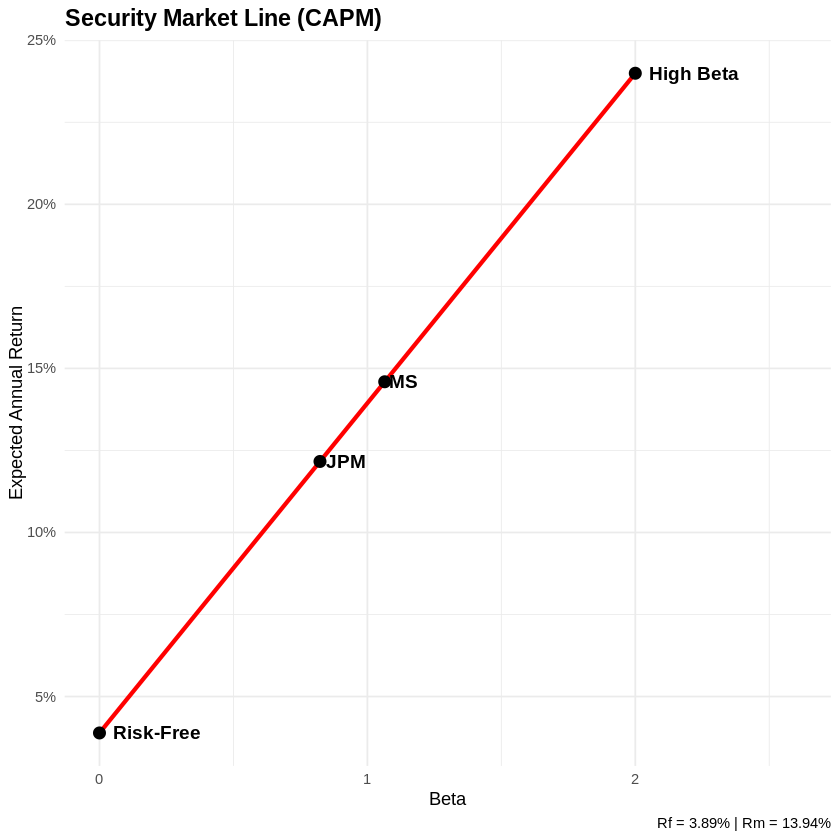

In [ ]:
library(ggplot2)

betas = c(0, beta_JPM, beta_MS, 2)
labels = c("Risk-Free", "JPM", "MS", "High Beta")
sml_df = data.frame(
  Beta = betas,
  Expected_Return = rf_annual + betas * (market_annual - rf_annual),
  Label = labels
)
sml_df = sml_df[order(sml_df$Beta), ]

ggplot(sml_df, aes(x = Beta, y = Expected_Return)) +
  geom_line(color = "red", linewidth = 1.2) +
  geom_point(size = 3) +
  geom_text(aes(label = Label), hjust = -0.15, vjust = 0.5, size = 4, fontface = "bold") +
  scale_x_continuous(limits = c(0, 2.6)) +
  scale_y_continuous(labels = scales::percent) +
  labs(
    title = "Security Market Line (CAPM)", x = "Beta", y = "Expected Annual Return",
    caption = sprintf("Rf = %.2f%% | Rm = %.2f%%", rf_annual * 100, market_annual * 100)
  ) +
  theme_minimal() +
  theme(plot.title = element_text(size = 14, face = "bold"), axis.title = element_text(size = 11))

Since all points lie on the SML, both ASC and AV are fairly valued under CAPM- they're delivering exactly the return their level of systematic risk justifies. Neither is over or underpriced relative to the market.

All four points sit exactly on the red SML line, evenly spaced along it.
AV's actual return > CAPM expected return - plots ABOVE the SML, means Underpriced
Security Market Line
It is a line drawn on a graph that represents the Capital Asset Pricing Model (CAPM) visually. It shows the relationship between:
Systematic risk (Beta) on the x-axis
Expected return on the y-axis

#Sharpe Ratio

In [ ]:
sharpe_jpm = mean(returns_df$JPM_excess, na.rm = TRUE) / sd(returns_df$JPM_return, na.rm = TRUE) *sqrt(252)
sharpe_ms = mean(returns_df$MS_excess, na.rm = TRUE) / sd(returns_df$MS_return, na.rm = TRUE) *sqrt(252)

#Rolling Beta
This gives you a series of betas over time rather than one single number

In [ ]:
library(zoo)

# Rolling 30-day beta for ASC
rolling_beta_jpm = rollapply(
  data = returns_df[, c("JPM_excess", "Market_excess")],
  width = 30,
  FUN = function(df) {
    if (anyNA(df)) return(NA)
    coef(lm(JPM_excess ~ Market_excess, data = as.data.frame(df)))[2]
  },
  by.column = FALSE,
  align = "right",
  fill = NA
)

# Rolling 30-day beta for AV
rolling_beta_ms = rollapply(
  data = returns_df[, c("MS_excess", "Market_excess")],
  width = 30,
  FUN = function(df) {
    if (anyNA(df)) return(NA)
    coef(lm(MS_excess ~ Market_excess, data = as.data.frame(df)))[2]
  },
  by.column = FALSE,
  align = "right",
  fill = NA
)

# Add back to the main dataframe
returns_df$Beta_JPM = rolling_beta_jpm
returns_df$Beta_MS = rolling_beta_ms

# Preview the result
tail(returns_df[, c("date", "Beta_JPM", "Beta_MS")])


date,Beta_JPM,Beta_MS
<date>,<dbl>,<dbl>
2026-03-06,1.260319,2.017250
2026-03-09,1.250447,1.987586
2026-03-10,1.235673,1.962399
2026-03-11,1.254169,1.968605
2026-03-12,1.240347,2.037525
2026-03-13,1.200493,1.951591


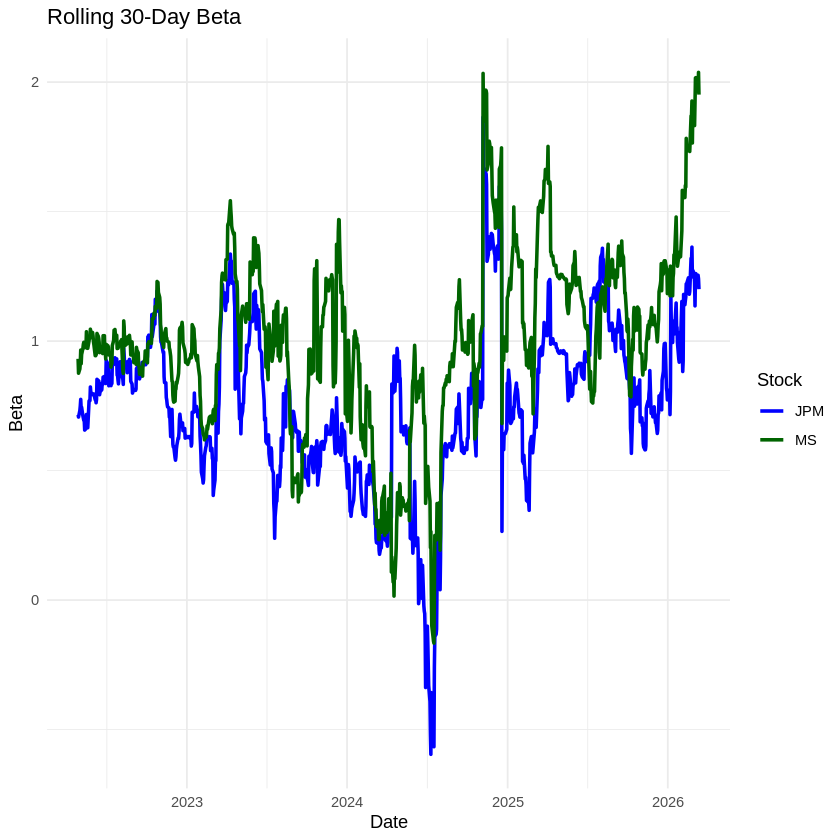

In [ ]:
library(ggplot2)
library(tidyr)
library(dplyr)

# Long format for plotting
rolling_beta_plot = returns_df %>%
  select(date, Beta_JPM, Beta_MS) %>%
  pivot_longer(cols = starts_with("Beta"), names_to = "Stock", values_to = "Beta") %>%
  filter(!is.na(Beta))  # remove missing values

# Plot
ggplot(rolling_beta_plot, aes(x = date, y = Beta, color = Stock)) +
  geom_line(linewidth = 1, na.rm = TRUE) +
  labs(title = "Rolling 30-Day Beta", x = "Date", y = "Beta") +
  scale_color_manual(values = c("Beta_JPM" = "blue", "Beta_MS" = "darkgreen"),
                     labels = c("JPM", "MS")) +
  theme_minimal()

#Portfolio Optimization

In [ ]:

# Extract return matrix
R = returns_df %>%
select(JPM_return, MS_return) %>%
na.omit() %>%
as.matrix()
colnames(R) = c("JPM", "MS")
# Calculate covariance matrix
cov_matrix = cov(R)
# MVP weights (analytical solution)
inv_cov = solve(cov_matrix)
ones = rep(1, ncol(R))
w_mvp = inv_cov %*% ones / as.numeric(t(ones) %*% inv_cov %*% ones)
w_mvp = as.vector(w_mvp / sum(w_mvp)) # normalize to sum to 1
# Output MVP weights
mvp_weights = tibble(
Asset = colnames(R),
MVP_Weight = round(w_mvp, 4)
)
print(mvp_weights)
# Use same return matrix and covariance
mean_returns = colMeans(R)
rf = rf_daily # already defined in your script
# MSR weights (analytical tangency portfolio)
excess_ret = mean_returns - rf
w_msr = inv_cov %*% excess_ret / as.numeric(t(ones) %*% inv_cov %*% excess_ret)
w_msr = as.vector(w_msr / sum(w_msr)) # normalize to sum to 1
# Output MSR weights
msr_weights = tibble(
Asset = colnames(R),
MSR_Weight = round(w_msr, 4)
)
print(msr_weights)


# A tibble: 2 × 2
  Asset MVP_Weight
  <chr>      <dbl>
1 JPM        0.771
2 MS         0.229
# A tibble: 2 × 2
  Asset MSR_Weight
  <chr>      <dbl>
1 JPM        1.10 
2 MS        -0.101


#Output

In [ ]:
# Step: Export All Metrics to CSV

# Individual stock metrics
individual_metrics = data.frame(
  Expected_Return = c(mean_jpm, mean_ms),
  Volatility = c(vol_jpm, vol_ms),
  Beta = c(beta_JPM, beta_MS),
  Max_Drawdown = c(mdd_jpm, mdd_ms),
  VaR_95 = c(var_95_jpm, var_95_ms),
  VaR_99 = c(var_99_jpm, var_99_ms),
  CVaR_95 = c(es_95_jpm, es_95_ms),
  CVaR_99 = c(es_99_jpm, es_99_ms),
  CAPM_Expected_Return = c(capm_JPM, capm_MS),
  Sharpe_Ratio = c(sharpe_jpm, sharpe_ms),
  row.names = c("JPM", "MS")
)

# Calculate portfolio metrics for MVP and MSR
# MVP metrics
mvp_return = sum(w_mvp * mean_returns * 252)
mvp_volatility = sqrt(t(w_mvp) %*% cov_matrix %*% w_mvp * 252)
mvp_sharpe = (mvp_return - rf_annual) / mvp_volatility

# MSR metrics
msr_return = sum(w_msr * mean_returns * 252)
msr_volatility = sqrt(t(w_msr) %*% cov_matrix %*% w_msr * 252)
msr_sharpe = (msr_return - rf_annual) / msr_volatility

# Portfolio optimization results
portfolio_results = data.frame(
  Weight_JPM = c(w_mvp[1], w_msr[1]),
  Weight_MS = c(w_mvp[2], w_msr[2]),
  Expected_Return = c(mvp_return, msr_return),
  Volatility = c(mvp_volatility, msr_volatility),
  Sharpe_Ratio = c(mvp_sharpe, msr_sharpe),
  row.names = c("MVP", "MSR")
)

# Rolling beta summary statistics
rolling_beta_summary = data.frame(
  Mean_Beta = c(
    mean(returns_df$Beta_JPM, na.rm = TRUE),
    mean(returns_df$Beta_MS, na.rm = TRUE)
  ),
  Median_Beta = c(
    median(returns_df$Beta_JPM, na.rm = TRUE),
    median(returns_df$Beta_MS, na.rm = TRUE)
  ),
  SD_Beta = c(
    sd(returns_df$Beta_JPM, na.rm = TRUE),
    sd(returns_df$Beta_MS, na.rm = TRUE)
  ),
  Min_Beta = c(
    min(returns_df$Beta_JPM, na.rm = TRUE),
    min(returns_df$Beta_MS, na.rm = TRUE)
  ),
  Max_Beta = c(
    max(returns_df$Beta_JPM, na.rm = TRUE),
    max(returns_df$Beta_MS, na.rm = TRUE)
  ),
  row.names = c("JPM", "MS")
)

# Export to CSV files
write.csv(individual_metrics, "r_individual_stock_metrics.csv")
write.csv(portfolio_results, "r_portfolio_optimization_results.csv")
write.csv(rolling_beta_summary, "r_rolling_beta_summary.csv")

# Export full rolling beta time series
rolling_beta_timeseries = returns_df %>%
  select(date, Beta_JPM, Beta_MS) %>%
  filter(!is.na(Beta_JPM) | !is.na(Beta_MS))

write.csv(rolling_beta_timeseries, "r_rolling_beta_timeseries.csv", row.names = FALSE)

# Display summary tables
cat("Data exported to CSV files:\n")
cat("1. r_individual_stock_metrics.csv - Individual stock analysis\n")
cat("2. r_portfolio_optimization_results.csv - Portfolio optimization results\n")
cat("3. r_rolling_beta_summary.csv - Rolling beta summary statistics\n")
cat("4. r_rolling_beta_timeseries.csv - Full rolling beta time series\n")

cat("\n=== INDIVIDUAL STOCK METRICS ===\n")
print(round(individual_metrics, 4))

cat("\n=== PORTFOLIO OPTIMIZATION RESULTS ===\n")
print(round(portfolio_results, 4))

cat("\n=== ROLLING BETA SUMMARY ===\n")
print(round(rolling_beta_summary, 4))

Data exported to CSV files:
1. r_individual_stock_metrics.csv - Individual stock analysis
2. r_portfolio_optimization_results.csv - Portfolio optimization results
3. r_rolling_beta_summary.csv - Rolling beta summary statistics
4. r_rolling_beta_timeseries.csv - Full rolling beta time series

=== INDIVIDUAL STOCK METRICS ===
    Expected_Return Volatility   Beta Max_Drawdown  VaR_95  VaR_99 CVaR_95
JPM          0.2105     0.2452 0.8231      -0.2851 -0.0233 -0.0432 -0.0358
MS           0.1728     0.2866 1.0647      -0.3018 -0.0268 -0.0507 -0.0409
    CVaR_99 CAPM_Expected_Return Sharpe_Ratio
JPM -0.0540               0.1216       0.7000
MS  -0.0623               0.1459       0.4671

=== PORTFOLIO OPTIMIZATION RESULTS ===
    Weight_JPM Weight_MS Expected_Return Volatility Sharpe_Ratio
MVP     0.7706    0.2294          0.2018     0.2407       0.6768
MSR     1.1006   -0.1006          0.2143     0.2498       0.7022

=== ROLLING BETA SUMMARY ===
    Mean_Beta Median_Beta SD_Beta Min_Beta Max